# Alpha diversity of the ITS fungal community

**Question.** Does alpha diversity of the fungal community differ between **sampling times** and among **plant genera**?

**Design.** 18 independent samples (each from a different soil): 3 plant genera × 2 times × 3 replicates.

| Factor | Levels | Taken from the sample name |
|---|---|---|
| `plant_genus` | E, T, R | 1st letter |
| `Time` | B, F | 2nd letter |
| replicate | 1, 2, 3 | 3rd character |

*Example: sample `EF1` = genus **E**, time **F**, replicate **1**.*

**Metrics**

| Metric | Formula | Variables |
|---|---|---|
| `Observed` | `S_obs` | `S_obs` = number of observed taxons/rows |
| `Chao1` | `S_obs + (f1² / 2f2)` | `f1` = number of singleton taxons/rows; `f2` = number of doubleton taxons/rows |
| `Shannon` | `H' = -Σ(p_i × ln(p_i))` | `p_i` = relative abundance of taxons/rows *i*; `S` = number of observed taxons/rows |
| `Pielou` | `J = H' / ln(S)` | `H'` = Shannon index; `S` = number of taxons/rows |


**Workflow**

1. Load libraries
2. Load ASV counts and taxonomy into a `phyloseq` object
3. Collapse ASVs to genus and calculate alpha diversity metrics
4. Descriptive statistics by **time**
5. Descriptive statistics by **genus × time**
6. Effect of time: **Wilcoxon** rank-sum test
7. Effect of genus within each time: **Kruskal-Wallis** test
8. Effect of time within each genus: **Wilcoxon** rank-sum test
9. Figure (boxplots)
10. Reading the results

## 1. Setup

The packages used throughout this notebook are loaded below. phyloseq is installed from Bioconductor, and vegan, openxlsx, dplyr, ggplot2, tibble and tidyr are available from CRAN.

Bioconductor:

BiocManager::install("phyloseq")

CRAN:

install.packages(c("vegan", "openxlsx", "dplyr", "ggplot2", "tidyr", "tibble"))

In [2]:
library(phyloseq)
library(vegan)
library(openxlsx)
library(dplyr)
library(ggplot2)
library(tidyr)
library(tibble)

---
## 2. Load the data

The Excel file has two sheets of interest: the **ASV count table** (rows = ASVs, columns = samples) and the **taxonomy** of each ASV. Sample metadata (genus and time) is read from the sample names here.

> The `stopifnot()` line stops the notebook if any ASV is missing from the taxonomy table.

In [2]:
asv <- read.xlsx("datasets/ITS_table_200.xlsx", sheet = "ITS-table", rowNames = TRUE)
asv[] <- lapply(asv, as.numeric)

tax <- read.xlsx("datasets/ITS_table_200.xlsx", sheet = "taxonomy", rowNames = TRUE)
colnames(tax) <- c("Kingdom", "Phylum", "Class", "Order", "Family", "Genus", "Species", "Strain")
stopifnot(all(rownames(asv) %in% rownames(tax)))

ps <- phyloseq(otu_table(asv, taxa_are_rows = TRUE), tax_table(as.matrix(tax)))

sample_data(ps) <- data.frame(
  plant_genus = factor(substr(sample_names(ps), 1, 1), levels = c("E", "T", "R")),
  Time        = factor(substr(sample_names(ps), 2, 2), levels = c("B", "F")),
  row.names   = sample_names(ps))

ps

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 7275 taxa and 18 samples ]
sample_data() Sample Data:       [ 18 samples by 2 sample variables ]
tax_table()   Taxonomy Table:    [ 7275 taxa by 8 taxonomic ranks ]

---
## 3. Genus level colapsing and alpha diversity metrics

- `tax_glom()` sums all ASVs that belong to the same genus, so every metric below describes **genus+ higher taxons** diversity (for example `Observed` is a number of genera + higher taxons that didn't resolve to genus level, not of direct ASVs). This is done because the data originates from DADA2 classifications on ITS sequences which usualy isn't enough to determine spiecies, much less strain.
- `NArm = FALSE` **keeps ASVs with no genus assignment** instead of dropping them, so their reads still count. This way we avoid further leakeage.
- `estimate_richness()` calculates `Observed`, `Chao1` (Chao 1984) and `Shannon` (Shannon 1948) for each sample from the counts as they are. The extra column `se.chao1` is the error of the Chao1 estimate.
- **Pielou's evenness** (Pielou 1966) is not provided by phyloseq, so it is calculated as `Shannon / log(Observed)`: Shannon diversity divided by the maximum it could reach with that number of rows.

> **Warning about singletons.** `estimate_richness()` warns that the data contain no singletons (genera with exactly 1 read in a sample). Chao1 ajusts for the number of missed genera from singletons and doubletons, so without singletons it adds nothing: `Chao1` is identical to `Observed` and `se.chao1` is 0 in every sample. `Chao1` is kept for completeness, but it carries no extra information.

In [3]:
ps <- tax_glom(ps, taxrank = "Genus", NArm = FALSE)

alpha <- estimate_richness(ps, measures = c("Chao1", "Observed", "Shannon"))
alpha$Pielou <- alpha$Shannon / log(alpha$Observed)

alpha$plant_genus <- sample_data(ps)$plant_genus
alpha$Time <- sample_data(ps)$Time

alpha

Warning message in estimate_richness(ps, measures = c("Chao1", "Observed", "Shannon")):
“The data you have provided does not have
any singletons. This is highly suspicious. Results of richness
estimates (for example) are probably unreliable, or wrong, if you have already
trimmed low-abundance taxa from the data.

We recommended that you find the un-trimmed data and retry.”


,Observed,Chao1,se.chao1,Shannon,Pielou,plant_genus,Time
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>
EF1,56,56,0,2.472900,0.6143314,E,F
EB1,96,96,0,2.981121,0.6531319,E,B
EF2,44,44,0,2.239385,0.5917741,E,F
EB2,94,94,0,2.983749,0.6567369,E,B
EF3,52,52,0,2.056628,0.5205014,E,F
EB3,95,95,0,2.881947,0.6328558,E,B
TF1,39,39,0,2.467976,0.6736547,T,F
TB1,76,76,0,2.962426,0.6840472,T,B
TF2,41,41,0,2.760967,0.7434800,T,F


---
## 4. Descriptive statistics by sampling time

For each metric, the mean, median, minimum, maximum and standard deviation are calculated separately for baseline (B) and final (F), pooling the three genera in one group (n = 9 per time).

- `group_by(Time)` splits the table by sampling time and `across()` applies the five summary functions to all four metrics.

In [4]:
metrics <- c("Chao1", "Observed", "Shannon", "Pielou")

des_Time <- alpha %>%
  group_by(Time) %>%
  summarise(
    across(
      all_of(metrics),
      list(
        Mean = ~mean(.x, na.rm = TRUE),
        Median = ~median(.x, na.rm = TRUE),
        Min = ~min(.x, na.rm = TRUE),
        Max = ~max(.x, na.rm = TRUE),
        SD = ~sd(.x, na.rm = TRUE))),
    .groups = "drop")

t(des_Time)

Time,B,F
Chao1_Mean,88.77778,53.66667
Chao1_Median,88,56
Chao1_Min,76,39
Chao1_Max,102,72
Chao1_SD,8.61362,10.80509
Observed_Mean,88.77778,53.66667
Observed_Median,88,56
Observed_Min,76,39
Observed_Max,102,72
Observed_SD,8.61362,10.80509


---
## 5. Descriptive statistics by plant genus and sampling time

The same summaries as above, now for each of the six plant genus separately (genus × time groups, n = 3 per group). 
> With only 3 samples per group, means and standard deviations are rough descriptions.

In [5]:
des_Genus_Time <- alpha %>%
  group_by(plant_genus, Time) %>%
  summarise(
    across(
      all_of(metrics),
      list(
        Mean = ~mean(.x, na.rm = TRUE),
        Median = ~median(.x, na.rm = TRUE),
        Min = ~min(.x, na.rm = TRUE),
        Max = ~max(.x, na.rm = TRUE),
        SD = ~sd(.x, na.rm = TRUE))),
    .groups = "drop")

t(des_Genus_Time)

plant_genus,E,E,T,T,R,R
Time,B,F,B,F,B,F
Chao1_Mean,95.00000,50.66667,79.33333,47.33333,92.00000,63.00000
Chao1_Median,95,52,79,41,88,60
Chao1_Min,94,44,76,39,86,57
Chao1_Max,96,56,83,62,102,72
Chao1_SD,1.000000,6.110101,3.511885,12.741010,8.717798,7.937254
Observed_Mean,95.00000,50.66667,79.33333,47.33333,92.00000,63.00000
Observed_Median,95,52,79,41,88,60
Observed_Min,94,44,76,39,86,57
Observed_Max,96,56,83,62,102,72


---
## 6. Effect of time: Wilcoxon rank-sum test

Do baseline (B) and final (F) samples differ in each metric, with all 18 samples pooled across all 3 plant genera (9 vs 9)?

- `wilcox.test(metric ~ Time)` is the **Wilcoxon rank-sum** test. It is rank-based, so it does not assume normality, and it is unpaired, which fits a design.
- `lapply()` repeats the test for each metric and `rbind()` stacks the results into one table.

In [10]:
wilcox_results <- do.call(rbind, lapply(metrics, \(m) {
  test <- wilcox.test(as.formula(paste(m, "~ Time")), data = alpha)
  data.frame(Metric = m, W = test$statistic, p = test$p.value)}))


print(wilcox_results, row.names = FALSE)

   Metric  W            p
    Chao1 81 4.113534e-05
 Observed 81 4.113534e-05
  Shannon 81 4.113534e-05
   Pielou 64 3.998355e-02


---
## 7. Effect of plant genus within each time: Kruskal-Wallis test

Do the three genera differ in each metric for the two seperate Time levels? Here the genera are compared **separately at baseline and at final** (3 genera × 3 replicates = 9 samples per test).

- `kruskal.test(metric ~ plant_genus)` performs a Kruskal–Wallis rank-sum test to assess whether the metrics differs among the plant-genus groups. `subset()` restricts the analysis to one time point at a time.

- The nested `lapply()` loops over every metric giving 4 metrics × 2 times = 8 rows. `Chi2` is the Kruskal-Wallis statistic (2 df).

> **Limitation.** With 3 samples per group, the chi-squared approximation behind the *p*-value is rough and the test has little power, so read these *p*-values as indicative.

In [7]:
kw_results <- do.call(rbind, lapply(metrics, \(m)
  do.call(rbind, lapply(c("B", "F"), \(t) {
    test <- kruskal.test(as.formula(paste(m, "~ plant_genus")),
                         data = subset(alpha, Time == t))
    data.frame(Metric = m, Time = t, Chi2 = test$statistic, p = test$p.value)}))))

print(kw_results, row.names = FALSE)

   Metric Time     Chi2          p
    Chao1    B 5.600000 0.06081006
    Chao1    F 3.288889 0.19311982
 Observed    B 5.600000 0.06081006
 Observed    F 3.288889 0.19311982
  Shannon    B 1.155556 0.56114397
  Shannon    F 4.355556 0.11329301
   Pielou    B 3.466667 0.17669445
   Pielou    F 5.422222 0.06646292


---
## 8. Effect of time within each plant genus: Wilcoxon rank-sum test

Is the baseline-final difference also visible within each genus on its own (3 vs 3 samples)? This is the same test as in section 6, repeated for each genus with `subset()`, giving 4 metrics × 3 genera = 12 rows.

> **Limitation.** Two groups of 3 can be arranged in only 20 ways, so the smallest possible two-sided *p*-value is **0.1** (it occurs at `W = 9` in this case, where all baseline samples are higher than all final samples). Use `W` and plots to judge how consistent the direction is, not the *p*-value alone.

In [8]:
wilcox_results_X <- do.call(rbind, lapply(metrics, \(m)
  do.call(rbind, lapply(c("E", "T", "R"), \(g) {
    test <- wilcox.test(as.formula(paste(m, "~ Time")),
                        data = subset(alpha, plant_genus == g))
    data.frame(Metric = m, Genus = g, W = test$statistic, p = test$p.value)}))))

print(wilcox_results_X, row.names = FALSE)

   Metric Genus W   p
    Chao1     E 9 0.1
    Chao1     T 9 0.1
    Chao1     R 9 0.1
 Observed     E 9 0.1
 Observed     T 9 0.1
 Observed     R 9 0.1
  Shannon     E 9 0.1
  Shannon     T 9 0.1
  Shannon     R 9 0.1
   Pielou     E 9 0.1
   Pielou     T 6 0.7
   Pielou     R 9 0.1


---
## 9. Figure: alpha diversity by plant genus and time

Boxplots of the four metrics for each genus, with baseline and final side by side. The individual samples are drawn as points, because each box summarises only 3 values.

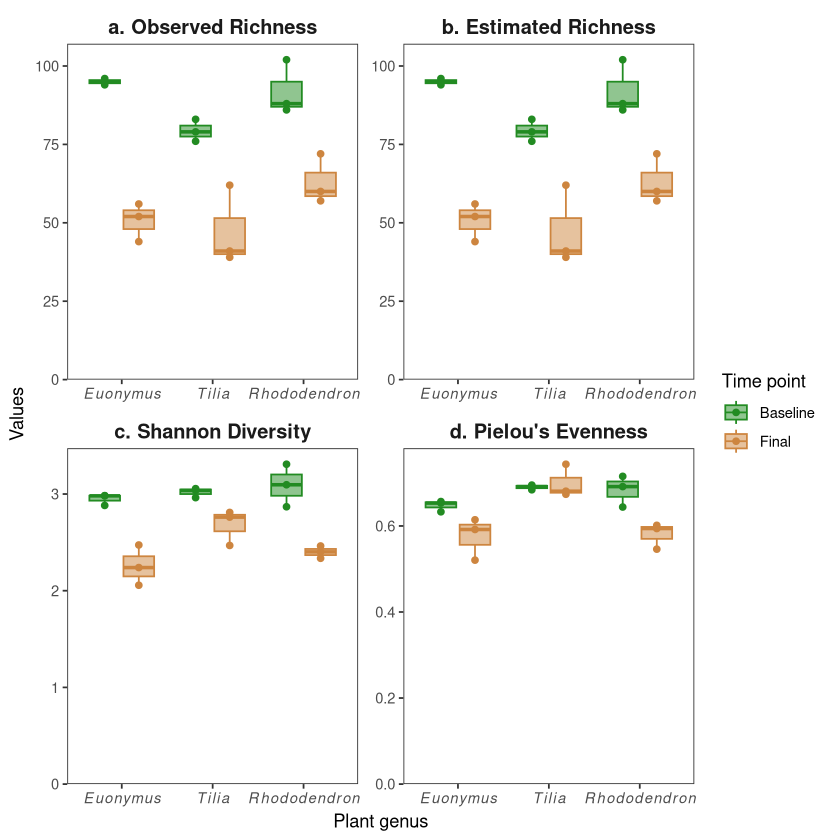

In [9]:
alpha_boxplot <- alpha %>%
  pivot_longer(c(Observed, Chao1, Shannon, Pielou),
               names_to = "Metric", values_to = "Value") %>%
  mutate(Metric = recode(Metric,
    Observed = "a. Observed Richness",
    Chao1 = "b. Estimated Richness",
    Shannon = "c. Shannon Diversity",
    Pielou = "d. Pielou's Evenness"))

ggplot(alpha_boxplot, aes(plant_genus, Value)) +
  geom_boxplot(aes(colour = Time, fill = Time), alpha = .5) +
  geom_point(aes(colour = Time), size = 1.5,
             position = position_jitterdodge(jitter.width = 0)) +
  facet_wrap(~Metric, scales = "free") +
  scale_x_discrete(labels = c(E = expression(italic(Euonymus)), R = expression(italic(Rhododendron)), T = expression(italic(Tilia)))) +
  scale_colour_manual(values = c(B = "forestgreen", F = "peru"),
                      labels = c(B = "Baseline", F = "Final")) +
  scale_fill_manual(values = c(B = "forestgreen", F = "peru"),
                    labels = c(B = "Baseline", F = "Final")) +
  labs(x = "Plant genus", y = "Values", colour = "Time point", fill = "Time point") +
  scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, .05))) +
  theme_bw() +
  theme(strip.background = element_blank(),
        strip.text = element_text(face = "bold", size = 12),
        panel.grid = element_blank())

---
## 10. Reading the results

**In short:** richness and Shannon diversity were lower at the final time point than at baseline in every genus, while the three genera did not differ significantly from each other at either time for these metrics (although at n = 3 its possible this was due to low power).

### Effect of time (all genera pooled n = 9)

| Observed (= Chao1) | Shannon | Pielou |
| --- | --- | --- |
| 88.78 → 53.67 (`W` = 81, *p* = 0.00004) | 3.02 → 2.45 (`W` = 81, *p* = 0.00004) | 0.67 → 0.62 (`W` = 64, *p* = 0.040) |

* Mean richness fell from 88.8 genera at baseline to 53.7 at final (≈ 40% lower; SD 8.6 and 10.8). Mean Shannon diversity fell from 3.02 to 2.45 and mean Pielou evenness from 0.674 to 0.618.
* For `Observed`, `Chao1` and `Shannon` the Wilcoxon test gave `W` = 81 and *p* = 4.1e-5. Every baseline sample is higher than every final sample, which is the strongest result possible with 9 vs 9 samples.
* The evenness effect is weaker (`W` = 64, *p* = 0.040) witch is attributed to the weaker separation of Baseline and Final samples in this metric's value (look at Tilia samples for example, section 9 plot)


### Effect of plant genus within each time

| Metric | Baseline (B) | Final (F) |
| --- | --- | --- |
| Observed / Chao1 | `Chi2` = 5.60, *p* = 0.061 | `Chi2` = 3.29, *p* = 0.19 |
| Shannon | `Chi2` = 1.16, *p* = 0.56 | `Chi2` = 4.36, *p* = 0.11 |
| Pielou | `Chi2` = 3.47, *p* = 0.18 | `Chi2` = 5.42, *p* = 0.066 |

* No Kruskal-Wallis test is significant, so we assume there are no significant differences among genera at either time, although power is low.

* The largest between-genus differences were observed for richness at baseline (*Chi2* = 5.60), where Tilia had the lowest richness (79.3 vs 95.0 in Euonymus and 92.0 in Rhododendron), and for Pielou evenness at final (*Chi2* =  5.42), where Tilia had the highest evenness (0.699 vs 0.576 in Euonymus and 0.580 in Rhododendron). Neither difference was statistically significant. Given the low sample size (3 samples per genus), these patterns are descriptive and do not provide sufficient evidence to conclude that the genera doesn't differ significantly.



### Effect of time within each genus

Values are the mean at baseline → final. `W` and *p* are from the Wilcoxon test (3 vs 3).

| Genus | Observed (= Chao1) | Shannon | Pielou |
| --- | --- | --- | --- |
| *Euonymus* (E) | 95.0 → 50.7 (`W` = 9, *p* = 0.1) | 2.95 → 2.26 (`W` = 9, *p* = 0.1) | 0.648 → 0.576 (`W` = 9, *p* = 0.1) |
| *Tilia* (T) | 79.3 → 47.3 (`W` = 9, *p* = 0.1) | 3.02 → 2.68 (`W` = 9, *p* = 0.1) | 0.690 → 0.699 (`W` = 6, *p* = 0.7) |
| *Rhododendron* (R) | 92.0 → 63.0 (`W` = 9, *p* = 0.1) | 3.09 → 2.40 (`W` = 9, *p* = 0.1) | 0.684 → 0.580 (`W` = 9, *p* = 0.1) |

* The direction is the same in all three genera: for richness and Shannon diversity, all 3 baseline samples are above all 3 final samples (`W` = 9). *p* = 0.1 is the smallest value possible for 3 vs 3, so no single genus can reach 0.05, however consistent the difference is.

* The size of the drop differs between genera. Richness fell by about 44 genera in E (≈ 47%), 32 in T (≈ 40%) and 29 in R (≈ 32%), and R keeps the highest richness at final (63, against 51 in E and 47 in T). This is descriptive only, the notebook does not test a genus × time interaction for alpha diversity.

* Pielou evenness is derived from Shannon diversity and richness (\(J'=H'/\ln(S)\)). In T, Pielou remained essentially unchanged (0.690 → 0.699), while richness declined from 79.3 to 47.3; therefore, the decrease in Shannon diversity (3.02 → 2.68) is better explained by the loss of richness rather than a decline in evenness. In E and R, both richness and Pielou decreased, so both components contributed to the reduction in Shannon diversity.







### References

* Chao, Anne. (1984). Non-parametric estimation of the classes in a population. Scandinavian Journal of Statistics. 11. 265-270. 10.2307/4615964. 
* McMurdie PJ, Holmes S (2013) phyloseq: An R Package for Reproducible Interactive Analysis and Graphics of Microbiome Census Data. PLOS ONE 8(4): e61217. https://doi.org/10.1371/journal.pone.0061217
* Oksanen J, Simpson G, Blanchet F, Kindt R, Legendre P, Minchin P, O'Hara R, Solymos P, Stevens M, Szoecs E, Wagner H, Bedward M, Bolker B, Borcard D, Carvalho G, De Caceres M, Durand S, Evangelista H, Hannigan G, Hill M, Lahti L, Martino C, Ouellette M, Ribeiro Cunha E, Smith T, Stier A, Ter Braak C, Weedon J (2026). _vegan: Community Ecology Package_. doi:10.32614/CRAN.package.vegan R package version 2.7-6 https://cran.r-project.org/package=vegan
* Pielou, E. C. (1966). The measurement of diversity in different types of biological collections. Journal of Theoretical Biology, 13, 131–144. doi:10.1016/0022-5193(66)90013-0
* Shannon, C. E. (1948). A mathematical theory of communication. The Bell System Technical Journal, 27(3), 379–423. doi:10.1002/j.1538-7305.1948.tb01338.x